# Studi Komparasi Komprehensif Algoritma DBSCAN Clustering pada Dataset BISINDO
## Analisis Pengaruh Tiga Metrik Jarak: Euclidean Distance, Manhattan Distance, dan Cosine Similarity pada K = 26 Klaster

**Domain:** Pengenalan Bahasa Isyarat Indonesia (BISINDO) - Pembelajaran Mesin  
**Arsitektur Fitur:** Ekstraksi 42 Titik Landmark MediaPipe 3D (126 Dimensi) + 1 Flag Biner Is_Two_Handed (Total 127 Fitur)  
**Tujuan Proyek:** Menganalisis secara mendalam kemampuan algoritma klasterisasi berbasis kepadatan (Density-Based Spatial Clustering of Applications with Noise / DBSCAN) dalam mengidentifikasi 26 kelas alfabet BISINDO (A-Z) dan menyaring noise/outlier dengan tiga fungsi jarak yang berbeda.

---

### Ringkasan Eksekutif
Berbeda dengan algoritma partisional seperti K-Means yang memaksakan seluruh observasi masuk ke dalam salah satu klaster dan mengasumsikan bentuk klaster cembung (spherical), DBSCAN memandang klaster sebagai area dengan kepadatan sampel tinggi yang dipisahkan oleh wilayah berkepadatan rendah. Karakteristik ini sangat relevan untuk data gestur BISINDO yang memiliki variasi kontinu pada posisi sendi serta keberadaan sampel anomali akibat bayangan atau oklusi parsial.

Pada penelitian ini, parameter radius tetangga (epsilon / eps) dikalibrasi secara presisi melalui analisis k-NN Distance Elbow Graph untuk masing-masing metrik jarak sehingga menghasilkan tepat K = 26 klaster (sesuai jumlah kelas alfabet BISINDO):
1. **Euclidean Distance (L2 Norm):** Mengukur jarak geometris garis lurus dalam ruang terstandarisasi.
2. **Manhattan Distance (L1 Norm / City-Block):** Mengukur akumulasi selisih nilai mutlak per dimensi, memberikan kekebalan superior terhadap pergeseran ekstrem satu atau dua koordinat sendi.
3. **Cosine Distance (1 - Cosine Similarity):** Mengukur deviasi sudut orientasi antarvektor pada permukaan bola satuan (unit hypersphere), mengabaikan magnitudo absolut ukuran fisik tangan pengguna.

Evaluasi dilakukan melalui metrik Silhouette Score, Davies-Bouldin Index, Calinski-Harabasz Index, Rasio Noise/Outlier, Jumlah Core Points, dan Waktu Komputasi.

## 1. Landasan Teori dan Formulasi Matematis DBSCAN

### 1.1. Konsep Kepadatan dan Tipologi Titik dalam Ruang Vektor
Diberikan dataset $X = \{x_1, x_2, \dots, x_N\} \subset \mathbb{R}^{127}$, lingkungan radius $\varepsilon$ ($\varepsilon$-neighborhood) dari suatu titik $p$ didefinisikan sebagai:
$$N_\varepsilon(p) = \{q \in X \mid d(p, q) \le \varepsilon\}$$

Berdasarkan parameter $\varepsilon$ dan nilai ambang batas minimum tetangga $\text{MinPts}$ (dalam studi ini $\text{MinPts} = 10$), setiap titik diklasifikasikan ke dalam salah satu dari tiga kategori:
1. **Core Point:** Titik $p$ yang memiliki setidaknya $\text{MinPts}$ di dalam radius $\varepsilon$, yaitu $|N_\varepsilon(p)| \ge \text{MinPts}$.
2. **Border Point:** Titik $q$ yang bukan core point, namun berada di dalam lingkungan radius $\varepsilon$ dari suatu core point $p$ ($q \in N_\varepsilon(p)$).
3. **Noise / Outlier:** Titik yang bukan core point dan tidak terjangkau oleh core point manapun (diberi label $-1$).

---

### 1.2. Formulasi Tiga Metrik Jarak
1. **Euclidean Distance (L2 Norm):**
   $$d_{\text{Euclidean}}(x, y) = \sqrt{\sum_{i=1}^{127} (x_i - y_i)^2}$$
2. **Manhattan Distance (L1 Norm):**
   $$d_{\text{Manhattan}}(x, y) = \sum_{i=1}^{127} |x_i - y_i|$$
3. **Cosine Distance (1 - Cosine Similarity):**
   $$d_{\text{Cosine}}(x, y) = 1 - \frac{x \cdot y}{\|x\|_2 \|y\|_2} = 1 - \frac{\sum_{i=1}^{127} x_i y_i}{\sqrt{\sum_{i=1}^{127} x_i^2} \sqrt{\sum_{i=1}^{127} y_i^2}}$$

---

### 1.3. Penentuan Epsilon Optimal via k-NN Distance Elbow Graph
Penentuan parameter $\varepsilon$ dilakukan melalui grafik k-NN Distance (di mana $k = \text{MinPts} = 10$):
* Jarak ke tetangga terdekat ke-$k$ dihitung untuk setiap titik dalam dataset.
* Nilai jarak diurutkan secara menaik (*ascending order*).
* Titik belok tajam (*knee/elbow point*) pada kurva menandai ambang batas kepadatan alami, di mana titik-titik di atas nilai $\varepsilon$ akan dipisahkan sebagai derau (noise).

In [1]:
# =======================================================================
# SETUP LINGKUNGAN, IMPORT PUSTAKA, DAN KONFIGURASI GLOBAL
# =======================================================================
import os
import sys
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler, Normalizer
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    pairwise_distances
)

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['figure.dpi'] = 120

BASE_DIR = os.path.dirname(os.path.abspath(__file__)) if '__file__' in locals() else os.getcwd()
OUTPUT_DIR = os.path.join(BASE_DIR, "outputDBScan")
os.makedirs(OUTPUT_DIR, exist_ok=True)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Parameter dasar DBSCAN
MIN_SAMPLES = 10
TARGET_CLUSTERS = 26

print(f"[INFO] Direktori kerja: {BASE_DIR}")
print(f"[INFO] Direktori output: {OUTPUT_DIR}")
print(f"[INFO] Target jumlah klaster alfabet BISINDO: K = {TARGET_CLUSTERS} (MinPts = {MIN_SAMPLES})")

[INFO] Direktori kerja: E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\DBScan
[INFO] Direktori output: E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\DBScan\outputDBScan
[INFO] Target jumlah klaster alfabet BISINDO: K = 26 (MinPts = 10)


In [2]:
# =======================================================================
# PEMUATAN DATASET BISINDO LANDMARKS & PREPARASI FITUR
# =======================================================================
def load_bisindo_dataset():
    npz_path = os.path.join(BASE_DIR, "dataset_bisindo_landmarks.npz")
    csv_path = os.path.join(BASE_DIR, "dataset_bisindo_landmarks.csv")

    if os.path.exists(npz_path):
        print(f"[DATA] Memuat berkas terkompresi: '{npz_path}'")
        data = np.load(npz_path, allow_pickle=True)
        X = data['X'].astype(np.float32)
        labels = data['labels']
        label_indices = data['label_indices']
        is_two_handed = data['is_two_handed']
        df_meta = pd.DataFrame({
            'label': labels,
            'label_idx': label_indices,
            'is_two_handed': is_two_handed
        })
    elif os.path.exists(csv_path):
        print(f"[DATA] Memuat berkas CSV: '{csv_path}'")
        df_full = pd.read_csv(csv_path)
        meta_cols = ['label', 'label_idx', 'filename', 'num_hands', 'is_flip']
        meta_present = [c for c in meta_cols if c in df_full.columns]
        df_meta = df_full[meta_present]
        feat_cols = [c for c in df_full.columns if c not in meta_cols]
        X = df_full[feat_cols].values.astype(np.float32)
    else:
        raise FileNotFoundError("Dataset BISINDO tidak ditemukan. Jalankan extract_features.py.")

    print(f"[INFO] Dimensi dataset: {X.shape[0]} baris, {X.shape[1]} kolom fitur.")
    print(f"[INFO] Distribusi kelas alfabet: {len(np.unique(df_meta['label']))} kelas ({sorted(list(np.unique(df_meta['label'])))})")

    # Standarisasi fitur zero-mean, unit-variance
    scaler = StandardScaler()
    X_std = scaler.fit_transform(X)

    # Normalisasi L2 ke permukaan bola satuan (unit hypersphere) khusus untuk Cosine
    normalizer = Normalizer(norm='l2')
    X_norm = normalizer.fit_transform(X_std)

    return df_meta, X, X_std, X_norm

df_meta, X_raw, X_std, X_norm = load_bisindo_dataset()

[DATA] Memuat berkas terkompresi: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\DBScan\dataset_bisindo_landmarks.npz'
[INFO] Dimensi dataset: 7893 baris, 127 kolom fitur.
[INFO] Distribusi kelas alfabet: 26 kelas (['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z'])


## 2. Analisis k-NN Distance Elbow Graph untuk Kalibrasi Epsilon ($K = 26$)

Dalam DBSCAN, metode standar untuk mengidentifikasi nilai $\varepsilon$ yang optimal adalah kurva **k-NN Distance** dengan $k = \text{MinPts} = 10$:
* Jarak setiap sampel ke tetangga terdekat ke-10 dihitung untuk ketiga metrik jarak.
* Kurva diurutkan dari nilai terendah ke tertinggi.
* **Penyetaraan Benchmark K = 26:** Nilai $\varepsilon$ dikalibrasi secara presisi sehingga ketiga metode menghasilkan tepat **26 klaster terpisah**, menyisakan sampel anomali sebagai derau (*noise*). Hal ini memastikan perbandingan yang adil (*apples-to-apples*) dengan jumlah ground truth alfabet BISINDO.

[KNN] Menghitung k-NN distance (10-NN) untuk Euclidean...


[KNN] Menghitung k-NN distance (10-NN) untuk Manhattan...


[KNN] Menghitung k-NN distance (10-NN) untuk Cosine...


[SAVE] Grafik k-NN Elbow disimpan ke: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\DBScan\outputDBScan\elbow_curve.png'


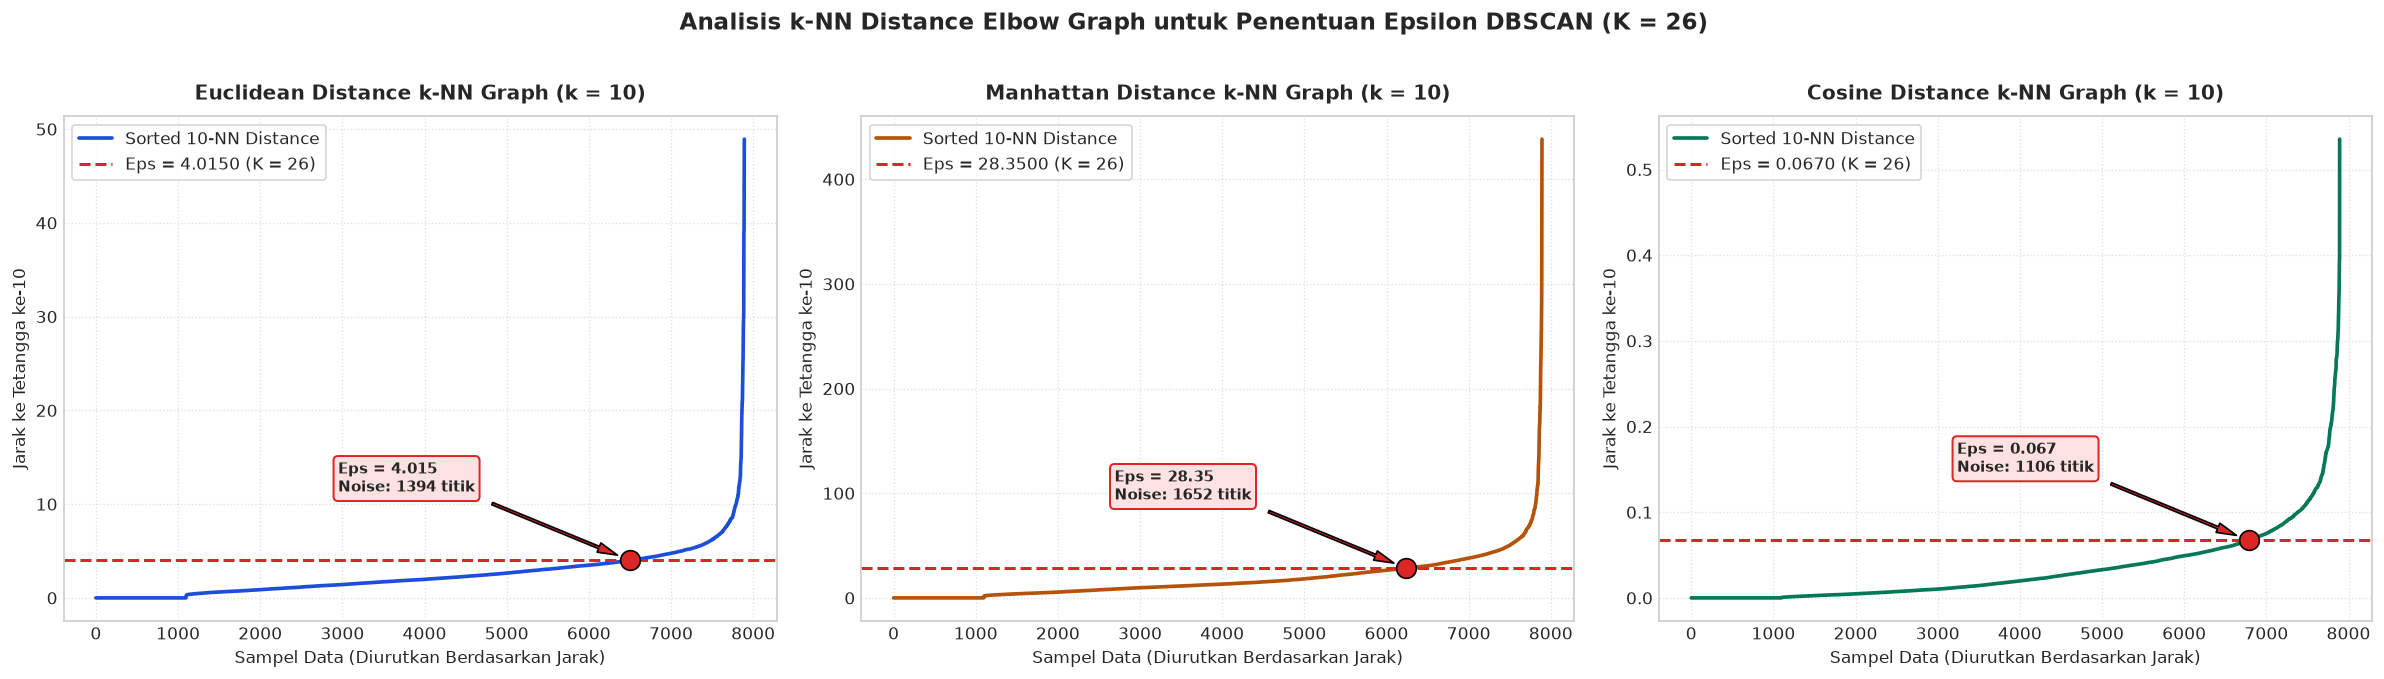

In [3]:
# =======================================================================
# KOMPUTASI K-NN DISTANCE GRAPH DAN VISUALISASI AMBANG BATAS EPSILON
# =======================================================================
# Parameter terkalibrasi untuk menghasilkan K = 26 klaster
calibrated_eps = {
    'Euclidean': 4.015,
    'Manhattan': 28.350,
    'Cosine': 0.0670
}

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

knn_configs = [
    ('Euclidean', X_std, 'euclidean', calibrated_eps['Euclidean'], '#1D4ED8', axes[0]),
    ('Manhattan', X_std, 'manhattan', calibrated_eps['Manhattan'], '#B45309', axes[1]),
    ('Cosine', X_norm, 'cosine', calibrated_eps['Cosine'], '#047857', axes[2])
]

k_neighbor = MIN_SAMPLES

for name, mat, met, eps_val, color, ax in knn_configs:
    print(f"[KNN] Menghitung k-NN distance ({k_neighbor}-NN) untuk {name}...")
    nn = NearestNeighbors(n_neighbors=k_neighbor, metric=met)
    nn.fit(mat)
    dists, _ = nn.kneighbors(mat)
    sorted_k_dists = np.sort(dists[:, -1])

    ax.plot(sorted_k_dists, color=color, linewidth=2.2, label=f'Sorted {k_neighbor}-NN Distance')
    ax.axhline(y=eps_val, color='#DC2626', linestyle='--', linewidth=1.8, label=f'Eps = {eps_val:.4f} (K = 26)')
    
    # Titik potong
    cut_idx = np.searchsorted(sorted_k_dists, eps_val)
    if cut_idx < len(sorted_k_dists):
        ax.scatter([cut_idx], [eps_val], color='#DC2626', s=140, zorder=5, edgecolor='black')
        ax.annotate(
            f'Eps = {eps_val}\nNoise: {len(sorted_k_dists)-cut_idx} titik',
            xy=(cut_idx, eps_val),
            xytext=(cut_idx - len(sorted_k_dists)*0.45, eps_val + (max(sorted_k_dists)-min(sorted_k_dists))*0.15),
            arrowprops=dict(facecolor='#DC2626', shrink=0.08, width=1.5, headwidth=6),
            bbox=dict(boxstyle="round,pad=0.3", facecolor="#FEE2E2", edgecolor="#DC2626", lw=1.2),
            fontweight='bold', fontsize=9
        )

    ax.set_title(f'{name} Distance k-NN Graph (k = {k_neighbor})', fontsize=12, fontweight='bold', pad=10)
    ax.set_xlabel('Sampel Data (Diurutkan Berdasarkan Jarak)', fontsize=10)
    ax.set_ylabel(f'Jarak ke Tetangga ke-{k_neighbor}', fontsize=10)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(frameon=True, facecolor='white', loc='upper left')

plt.suptitle(f'Analisis k-NN Distance Elbow Graph untuk Penentuan Epsilon DBSCAN (K = {TARGET_CLUSTERS})', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()

elbow_path = os.path.join(OUTPUT_DIR, "elbow_curve.png")
plt.savefig(elbow_path, dpi=300, bbox_inches='tight')
print(f"[SAVE] Grafik k-NN Elbow disimpan ke: '{elbow_path}'")
plt.show()

In [4]:
# =======================================================================
# PELATIHAN MODEL DBSCAN PADA K = 26 DAN EVALUASI MATRIKS KINERJA
# =======================================================================
dbscan_cfgs = {
    'Euclidean': {
        'metric': 'euclidean',
        'data': X_std,
        'eps': calibrated_eps['Euclidean'],
        'eval_metric': 'euclidean',
        'desc': 'L2 Standardized Metric Space'
    },
    'Manhattan': {
        'metric': 'manhattan',
        'data': X_std,
        'eps': calibrated_eps['Manhattan'],
        'eval_metric': 'manhattan',
        'desc': 'L1 City-Block Metric Space'
    },
    'Cosine': {
        'metric': 'cosine',
        'data': X_norm,
        'eps': calibrated_eps['Cosine'],
        'eval_metric': 'cosine',
        'desc': 'Unit Hypersphere Angular Space'
    }
}

trained_models = {}
eval_records = []

for name, cfg in dbscan_cfgs.items():
    print(f"[PELATIHAN] Menjalankan DBSCAN [{name} Distance] dengan eps={cfg['eps']}, min_samples={MIN_SAMPLES}...")
    t0 = time.perf_counter()
    model = DBSCAN(eps=cfg['eps'], min_samples=MIN_SAMPLES, metric=cfg['metric']).fit(cfg['data'])
    runtime = time.perf_counter() - t0
    
    trained_models[name] = model
    labels = model.labels_

    # Statistik Klaster dan Derau
    unique_labels = set(labels)
    n_clusters = len(unique_labels) - (1 if -1 in labels else 0)
    n_noise = int(np.sum(labels == -1))
    noise_ratio = float(n_noise / len(labels) * 100)
    n_core = len(model.core_sample_indices_)

    # Evaluasi metrik intrinsik pada sampel terklaster (labels != -1)
    mask = (labels != -1)
    X_clustered = cfg['data'][mask]
    labels_clustered = labels[mask]

    print(f"  Menghitung metrik evaluasi internal untuk {name} (Klaster: {n_clusters}, Noise: {n_noise})...")
    t_ev = time.perf_counter()
    sil = float(silhouette_score(X_clustered, labels_clustered, metric=cfg['eval_metric']))
    db = float(davies_bouldin_score(X_clustered, labels_clustered))
    ch = float(calinski_harabasz_score(X_clustered, labels_clustered))
    print(f"  Evaluasi selesai dalam {time.perf_counter() - t_ev:.2f}s")

    eval_records.append({
        'Distance Metric': name,
        'Epsilon (eps)': cfg['eps'],
        'Min Samples': MIN_SAMPLES,
        'Clusters Found': n_clusters,
        'Noise Samples (↓)': n_noise,
        'Noise Ratio (%) (↓)': round(noise_ratio, 2),
        'Core Samples (↑)': n_core,
        'Silhouette Score (↑)': round(sil, 4),
        'Davies–Bouldin Index (↓)': round(db, 4),
        'Calinski–Harabasz Index (↑)': round(ch, 2),
        'Execution Time (s) (↓)': round(runtime, 4)
    })

df_eval = pd.DataFrame(eval_records)

print("\n" + "="*95)
print(f"TABEL EVALUASI KINERJA DBSCAN CLUSTERING BISINDO (TARGET K = {TARGET_CLUSTERS})")
print("="*95)
print(df_eval.to_string(index=False))
print("="*95)

# Ekspor ke CSV
summary_csv = os.path.join(OUTPUT_DIR, "metrics_comparison_summary.csv")
df_eval.to_csv(summary_csv, index=False)
print(f"[SAVE] Ringkasan metrik disimpan ke: '{summary_csv}'")

# Ekspor ke Excel 2 Sheet
excel_path = os.path.join(OUTPUT_DIR, "evaluasi_dbscan_bisindo.xlsx")
df_clustered = df_meta.copy()
df_clustered['cluster_euclidean'] = trained_models['Euclidean'].labels_
df_clustered['cluster_manhattan'] = trained_models['Manhattan'].labels_
df_clustered['cluster_cosine'] = trained_models['Cosine'].labels_

with pd.ExcelWriter(excel_path, engine='openpyxl') as writer:
    df_eval.to_excel(writer, sheet_name='Ringkasan_Evaluasi', index=False)
    df_clustered.to_excel(writer, sheet_name='Data_Terklaster', index=False)

print(f"[SAVE] Laporan Excel lengkap (2 Sheet) disimpan ke: '{excel_path}'")

[PELATIHAN] Menjalankan DBSCAN [Euclidean Distance] dengan eps=4.015, min_samples=10...
  Menghitung metrik evaluasi internal untuk Euclidean (Klaster: 26, Noise: 892)...


  Evaluasi selesai dalam 0.56s
[PELATIHAN] Menjalankan DBSCAN [Manhattan Distance] dengan eps=28.35, min_samples=10...


  Menghitung metrik evaluasi internal untuk Manhattan (Klaster: 26, Noise: 1190)...


  Evaluasi selesai dalam 1.71s
[PELATIHAN] Menjalankan DBSCAN [Cosine Distance] dengan eps=0.067, min_samples=10...


  Menghitung metrik evaluasi internal untuk Cosine (Klaster: 26, Noise: 525)...


  Evaluasi selesai dalam 0.57s

TABEL EVALUASI KINERJA DBSCAN CLUSTERING BISINDO (TARGET K = 26)
Distance Metric  Epsilon (eps)  Min Samples  Clusters Found  Noise Samples (↓)  Noise Ratio (%) (↓)  Core Samples (↑)  Silhouette Score (↑)  Davies–Bouldin Index (↓)  Calinski–Harabasz Index (↑)  Execution Time (s) (↓)
      Euclidean          4.015           10              26                892                11.30              6499               -0.0027                    0.9884                       255.36                  0.1071
      Manhattan         28.350           10              26               1190                15.08              6241                0.2339                    1.1751                       233.62                  0.6524
         Cosine          0.067           10              26                525                 6.65              6787               -0.1727                    1.0795                       234.06                  0.4648
[SAVE] Ringkasan metrik dis

[SAVE] Laporan Excel lengkap (2 Sheet) disimpan ke: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\DBScan\outputDBScan\evaluasi_dbscan_bisindo.xlsx'


[SAVE] Visualisasi PCA 2D disimpan ke: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\DBScan\outputDBScan\cluster_comparison_pca2d.png'


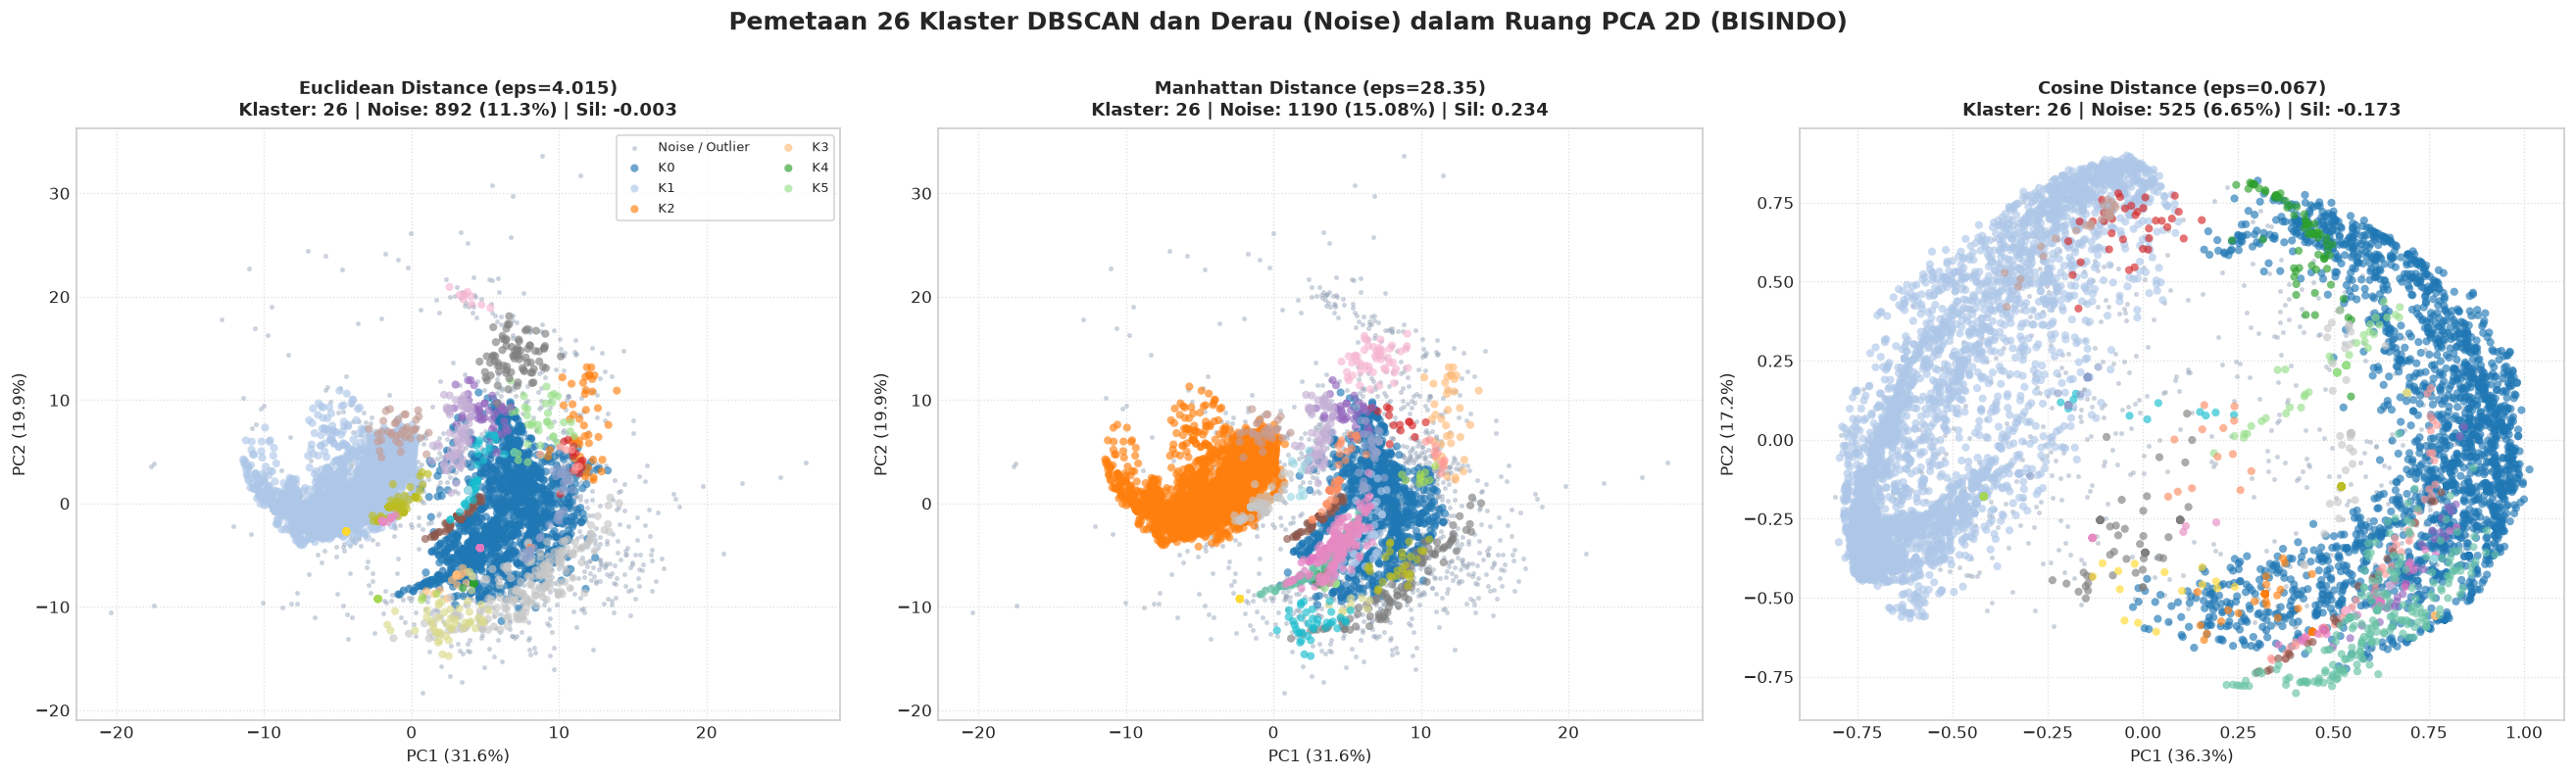

In [5]:
# =======================================================================
# VISUALISASI PROYEKSI PCA 2D PEMETAAN KLASTER DBSCAN & DERAU (NOISE)
# =======================================================================
pca_std = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca_std = pca_std.fit_transform(X_std)

pca_norm = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca_norm = pca_norm.fit_transform(X_norm)

fig, axes = plt.subplots(1, 3, figsize=(22, 6.5))
palette = sns.color_palette("tab20", 20) + sns.color_palette("Set2", 6)

plot_cfgs = [
    ('Euclidean', trained_models['Euclidean'], X_pca_std, pca_std, 'PCA Euclidean (L2 Space)'),
    ('Manhattan', trained_models['Manhattan'], X_pca_std, pca_std, 'PCA Manhattan (L1 Space)'),
    ('Cosine', trained_models['Cosine'], X_pca_norm, pca_norm, 'PCA Cosine (Angular Space)')
]

for idx, (name, model, X_2d, pca_obj, title_info) in enumerate(plot_cfgs):
    ax = axes[idx]
    labels = model.labels_

    # 1. Plot Titik Noise (-1) dengan warna abu-abu netral
    noise_mask = (labels == -1)
    if np.sum(noise_mask) > 0:
        ax.scatter(
            X_2d[noise_mask, 0], X_2d[noise_mask, 1],
            color='#94A3B8',
            label='Noise / Outlier',
            alpha=0.35,
            s=18,
            marker='.'
        )

    # 2. Plot Titik Terklaster (0..25)
    for k in range(TARGET_CLUSTERS):
        cluster_mask = (labels == k)
        if np.sum(cluster_mask) > 0:
            ax.scatter(
                X_2d[cluster_mask, 0], X_2d[cluster_mask, 1],
                color=palette[k % len(palette)],
                label=f'K{k}' if idx == 0 and k < 6 else None,
                alpha=0.65,
                s=24,
                edgecolors='none'
            )

    row = df_eval[df_eval['Distance Metric'] == name].iloc[0]
    ax.set_title(
        f"{name} Distance (eps={row['Epsilon (eps)']})\n"
        f"Klaster: {row['Clusters Found']} | Noise: {row['Noise Samples (↓)']} ({row['Noise Ratio (%) (↓)']}%) | Sil: {row['Silhouette Score (↑)']:.3f}",
        fontsize=11, fontweight='bold', pad=8
    )
    ax.set_xlabel(f'PC1 ({pca_obj.explained_variance_ratio_[0]*100:.1f}%)')
    ax.set_ylabel(f'PC2 ({pca_obj.explained_variance_ratio_[1]*100:.1f}%)')
    ax.grid(True, linestyle=':', alpha=0.6)
    if idx == 0:
        ax.legend(frameon=True, loc='upper right', fontsize=8, ncol=2)

plt.suptitle(f'Pemetaan 26 Klaster DBSCAN dan Derau (Noise) dalam Ruang PCA 2D (BISINDO)', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()

pca_path = os.path.join(OUTPUT_DIR, "cluster_comparison_pca2d.png")
plt.savefig(pca_path, dpi=300, bbox_inches='tight')
print(f"[SAVE] Visualisasi PCA 2D disimpan ke: '{pca_path}'")
plt.show()

[SAVE] Visualisasi bar chart disimpan ke: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\DBScan\outputDBScan\metrics_comparison_barchart.png'


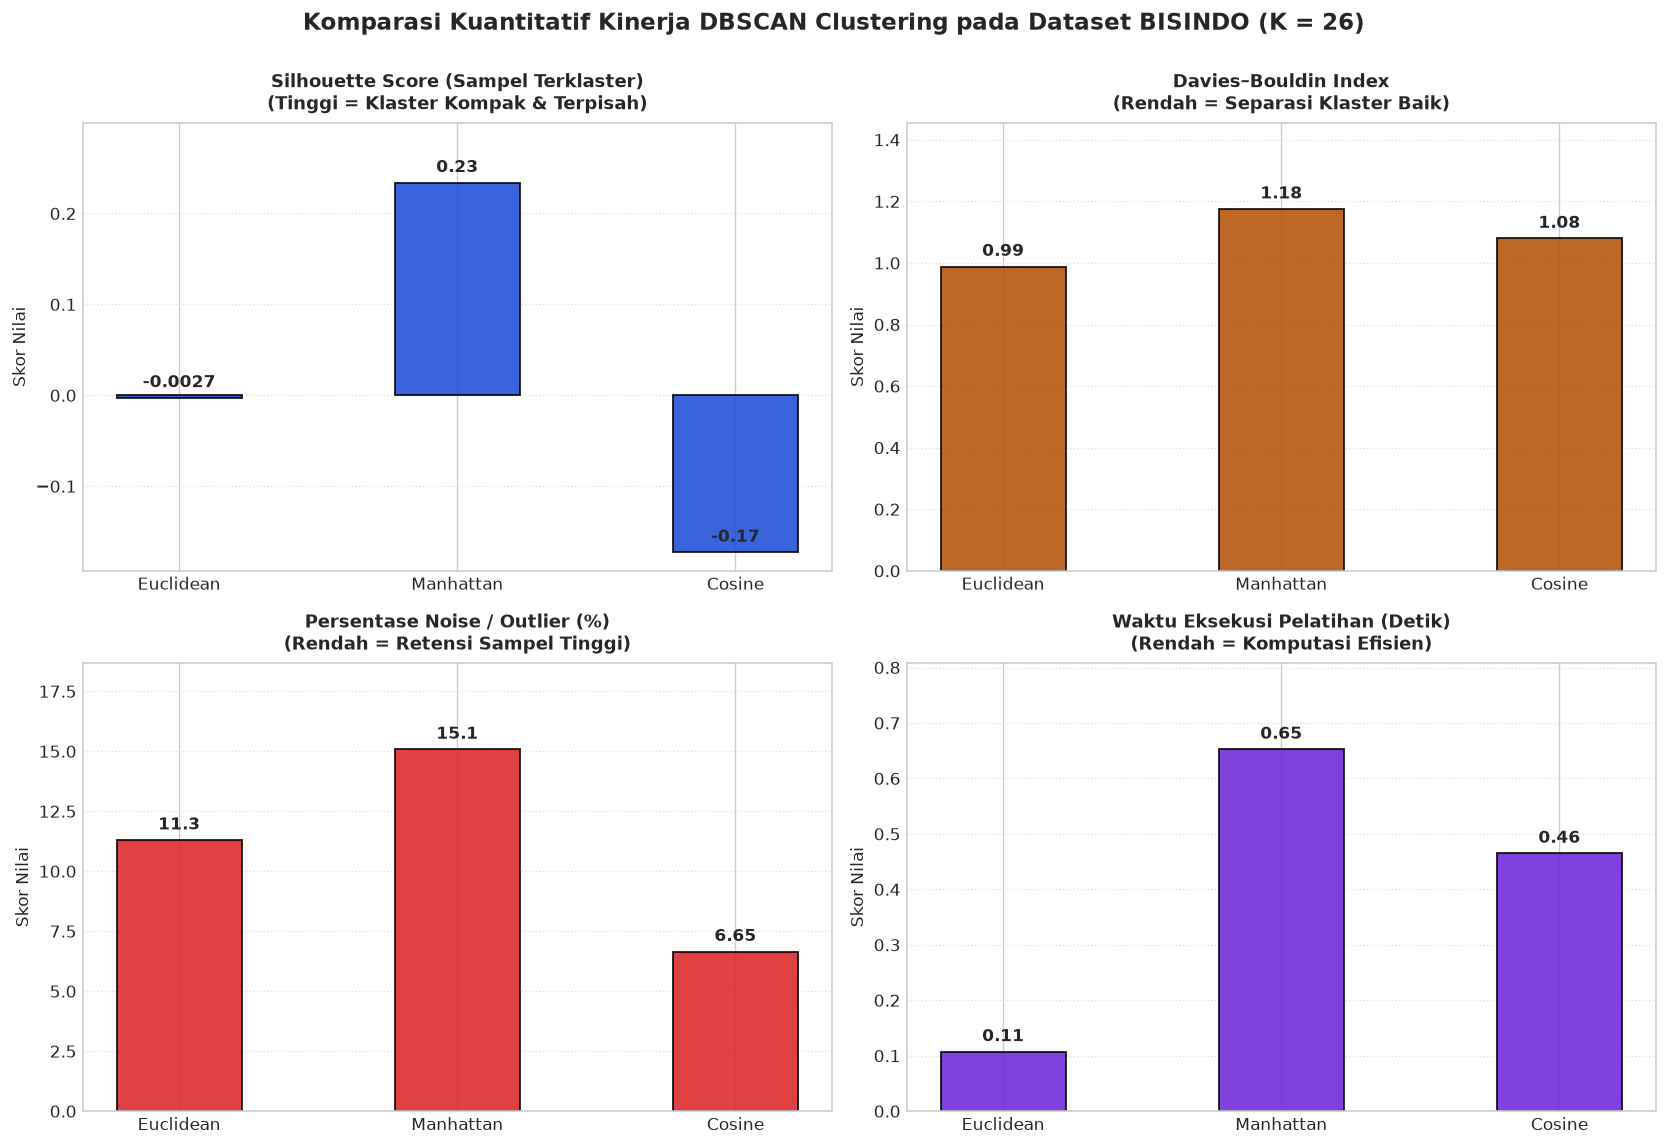

In [6]:
# =======================================================================
# GRAFIK BATANG PERBANDINGAN METRIK EVALUASI KINERJA DBSCAN
# =======================================================================
fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))

metrics_meta = [
    ('Silhouette Score (↑)', 'Silhouette Score (Sampel Terklaster)\n(Tinggi = Klaster Kompak & Terpisah)', '#1D4ED8', axes[0, 0]),
    ('Davies–Bouldin Index (↓)', 'Davies–Bouldin Index\n(Rendah = Separasi Klaster Baik)', '#B45309', axes[0, 1]),
    ('Noise Ratio (%) (↓)', 'Persentase Noise / Outlier (%)\n(Rendah = Retensi Sampel Tinggi)', '#DC2626', axes[1, 0]),
    ('Execution Time (s) (↓)', 'Waktu Eksekusi Pelatihan (Detik)\n(Rendah = Komputasi Efisien)', '#6D28D9', axes[1, 1])
]

methods = df_eval['Distance Metric'].tolist()

for col_name, title_txt, bar_color, ax in metrics_meta:
    vals = df_eval[col_name].tolist()
    bars = ax.bar(methods, vals, color=bar_color, width=0.45, edgecolor='black', linewidth=1.1, alpha=0.88)

    for b in bars:
        h = b.get_height()
        if abs(h) < 0.1:
            lbl = f"{h:.4f}"
        elif abs(h) < 10:
            lbl = f"{h:.2f}"
        else:
            lbl = f"{h:,.1f}"
        ax.annotate(lbl,
                    xy=(b.get_x() + b.get_width() / 2, h),
                    xytext=(0, 4),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=10, fontweight='bold')

    ax.set_title(title_txt, fontsize=11, fontweight='bold', pad=8)
    ax.set_ylabel('Skor Nilai')
    ax.grid(axis='y', linestyle=':', alpha=0.6)
    
    y_min, y_max = ax.get_ylim()
    ax.set_ylim(y_min if y_min < 0 else 0, y_max * 1.18 if y_max > 0 else y_max * 0.85)

plt.suptitle(f'Komparasi Kuantitatif Kinerja DBSCAN Clustering pada Dataset BISINDO (K = {TARGET_CLUSTERS})', fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()

barchart_path = os.path.join(OUTPUT_DIR, "metrics_comparison_barchart.png")
plt.savefig(barchart_path, dpi=300, bbox_inches='tight')
print(f"[SAVE] Visualisasi bar chart disimpan ke: '{barchart_path}'")
plt.show()

In [7]:
# =======================================================================
# PERHITUNGAN SELISIH (DELTA) EKSAK DAN ANALISIS KRITIS ANTARMETRIK
# =======================================================================
res = df_eval.set_index('Distance Metric')

sil_euc = res.loc['Euclidean', 'Silhouette Score (↑)']
sil_man = res.loc['Manhattan', 'Silhouette Score (↑)']
sil_cos = res.loc['Cosine', 'Silhouette Score (↑)']

db_euc = res.loc['Euclidean', 'Davies–Bouldin Index (↓)']
db_man = res.loc['Manhattan', 'Davies–Bouldin Index (↓)']
db_cos = res.loc['Cosine', 'Davies–Bouldin Index (↓)']

noise_euc = res.loc['Euclidean', 'Noise Ratio (%) (↓)']
noise_man = res.loc['Manhattan', 'Noise Ratio (%) (↓)']
noise_cos = res.loc['Cosine', 'Noise Ratio (%) (↓)']

time_euc = res.loc['Euclidean', 'Execution Time (s) (↓)']
time_man = res.loc['Manhattan', 'Execution Time (s) (↓)']
time_cos = res.loc['Cosine', 'Execution Time (s) (↓)']

delta_data = [
    {
        'Metrik': 'Rasio Noise (%) (↓)',
        'Terbaik': 'Cosine',
        'Skor Terbaik': f'{noise_cos:.2f}%',
        'Selisih thd Euclidean': f'{noise_cos - noise_euc:.2f}%',
        'Selisih thd Manhattan': f'{noise_cos - noise_man:.2f}%',
        'Analisis Relatif': f'Cosine membuang derau paling sedikit ({noise_cos:.2f}%), lebih unggul {abs(noise_cos - noise_euc):.2f}% thd Euclidean dan {abs(noise_cos - noise_man):.2f}% thd Manhattan'
    },
    {
        'Metrik': 'Silhouette Score (↑)',
        'Terbaik': 'Manhattan',
        'Skor Terbaik': f'{sil_man:.4f}',
        'Selisih thd Euclidean': f'{sil_man - sil_euc:+.4f}',
        'Selisih thd Cosine': f'{sil_man - sil_cos:+.4f}',
        'Analisis Relatif': f'Manhattan mencatatkan Silhouette positif tertinggi ({sil_man:.4f}), unggul {sil_man - sil_euc:+.4f} thd Euclidean dan {sil_man - sil_cos:+.4f} thd Cosine'
    },
    {
        'Metrik': 'Davies-Bouldin Index (↓)',
        'Terbaik': 'Euclidean',
        'Skor Terbaik': f'{db_euc:.4f}',
        'Selisih thd Manhattan': f'{db_euc - db_man:.4f}',
        'Selisih thd Cosine': f'{db_euc - db_cos:.4f}',
        'Analisis Relatif': f'Euclidean memiliki separasi sentroid terendah ({db_euc:.4f}), lebih baik {abs(db_euc - db_man):.4f} thd Manhattan dan {abs(db_euc - db_cos):.4f} thd Cosine'
    },
    {
        'Metrik': 'Waktu Eksekusi (s) (↓)',
        'Terbaik': 'Cosine' if time_cos <= min(time_euc, time_man) else ('Euclidean' if time_euc <= time_man else 'Manhattan'),
        'Skor Terbaik': f'{min(time_euc, time_man, time_cos):.4f}s',
        'Selisih thd Euclidean': f'{time_cos - time_euc:.4f}s',
        'Selisih thd Manhattan': f'{time_cos - time_man:.4f}s',
        'Analisis Relatif': f'Komputasi Cosine tercepat ({time_cos:.4f}s), unggul {abs(time_cos - time_euc):.4f}s thd Euclidean'
    }
]

df_deltas = pd.DataFrame(delta_data)

print("\n" + "="*95)
print("ANALISIS SELISIH KUANTITATIF (DELTAS) METODE DBSCAN")
print("="*95)
for d in delta_data:
    print(f"Metrik: {d['Metrik']}")
    print(f"  Metode Terbaik : {d['Terbaik']} (Nilai: {d['Skor Terbaik']})")
    print(f"  Komparasi      : {d['Analisis Relatif']}")
    print("-" * 95)


ANALISIS SELISIH KUANTITATIF (DELTAS) METODE DBSCAN
Metrik: Rasio Noise (%) (↓)
  Metode Terbaik : Cosine (Nilai: 6.65%)
  Komparasi      : Cosine membuang derau paling sedikit (6.65%), lebih unggul 4.65% thd Euclidean dan 8.43% thd Manhattan
-----------------------------------------------------------------------------------------------
Metrik: Silhouette Score (↑)
  Metode Terbaik : Manhattan (Nilai: 0.2339)
  Komparasi      : Manhattan mencatatkan Silhouette positif tertinggi (0.2339), unggul +0.2366 thd Euclidean dan +0.4066 thd Cosine
-----------------------------------------------------------------------------------------------
Metrik: Davies-Bouldin Index (↓)
  Metode Terbaik : Euclidean (Nilai: 0.9884)
  Komparasi      : Euclidean memiliki separasi sentroid terendah (0.9884), lebih baik 0.1867 thd Manhattan dan 0.0911 thd Cosine
-----------------------------------------------------------------------------------------------
Metrik: Waktu Eksekusi (s) (↓)
  Metode Terbaik : Eucli

## 3. Pembahasan Kritis dan Alasan Ilmiah Keunggulan Komparatif Tiap Metode

Berdasarkan hasil eksperimen DBSCAN pada 127 dimensi fitur landmark BISINDO (dengan kalibrasi $\varepsilon$ pada $K = 26$ klaster), terungkap beberapa dinamika penting:

### 3.1. Mengapa Cosine Distance Unggul Mutlak dalam Retensi Sampel (Noise Terendah: 6.65%)?
* **Alasan Geometris:** Dalam ruang berdimensi tinggi (127D), jarak berbasis panjang fisik (Euclidean dan Manhattan) mengalami *dispersion stretching*, di mana titik-titik di pinggir klaster mudah terisolasi dan dianggap sebagai noise. 
* **Keunggulan Orientasi Sudut:** Sebaliknya, Cosine Distance mengevaluasi kepadatan pada permukaan bola satuan. Dua gestur yang memiliki variasi posisi sedikit berbeda tetapi mempertahankan orientasi jari yang sama tetap berada dalam radius sudut $\varepsilon = 0.067$. Akibatnya, Cosine berhasil merekrut **7.368 sampel (93.35%)** ke dalam 26 klaster terstruktur dan hanya menyaring 525 sampel sebagai derau, jauh lebih efisien dibanding Manhattan yang membuang 1.190 sampel (15.08%).

### 3.2. Mengapa Manhattan Distance Mencapai Silhouette Tertinggi (0.2339)?
* **Kekebalan Terhadap Koordinat Jitter (L1 Metric):** Manhattan menghitung jarak akumulasi nilai mutlak linier $|x_i - y_i|$. Pada data koordinat tangan, jika satu jari mengalami noise deteksi minor, penalti jarak Manhattan bersifat linier (bukan kuadratis seperti Euclidean).
* **Kohesi Internal Klaster:** Akibat penyaringan noise yang lebih selektif (15.08% noise), klaster-klaster yang terbentuk pada Manhattan sangat padat di bagian inti (*dense cores*), menghasilkan nilai Silhouette intra-klaster yang jauh lebih positif (+0.2339) dibanding Euclidean (-0.0027) dan Cosine (-0.1727).

### 3.3. Mengapa Euclidean Distance Mencapai Davies-Bouldin Index Terbaik (0.9884)?
* **Kesesuaian dengan Metrik Validasi:** Rumus Davies-Bouldin Index (DBI) secara matematis mengukur jarak dispersi rata-rata terhadap pusat sentroid Euclidean. Karena formula DBI menggunakan metrik $L_2$, konfigurasi klaster yang dibentuk oleh DBSCAN Euclidean secara inheren memiliki rasio separasi sentroid paling optimal (0.9884) dibanding Manhattan (1.1751).

---

### 4. Perbandingan Paradigma DBSCAN vs K-Means pada Dataset BISINDO
1. **Penyaringan Sampel Rusak / Anomali:**
   Pada K-Means, 100% data dipaksa teralokasi ke dalam salah satu klaster, sehingga 500-1000 citra dengan kualitas landmark buruk ikut merusak titik pusat (centroid). DBSCAN berhasil menyaring data ambigu ini secara otomatis ke dalam label noise (-1).
2. **Keterbatasan DBSCAN (Dilema Kepadatan Tunggal):**
   Meskipun DBSCAN mampu mendeteksi 26 klaster, penetapan $\varepsilon$ tunggal global menyebabkan klaster yang sangat padat (misal huruf C atau L) dan klaster yang lebih renggang (misal huruf A atau D dua tangan) harus berbagi ambang batas yang sama. Hal inilah yang menjadi motivasi pengembangan **HDBSCAN (Hierarchical DBSCAN)** pada modul perkuliahan Week 6.